<a href="https://colab.research.google.com/github/escastel/bigdata_notebooks/blob/main/visualizacion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualización de datos
**Autora: Ester Castellano Ríos**

El objetivo de esta práctica es elegir 5 gráficos (charts) e implementar en el cuaderno esos 5 tipos de gráficos en Matplotlib y en Seaborn para comparar las dos bibliotecas gráficas.

Después, implementaremos StreamLit para visualizar esas 5 gráficas.

## Kaggle

**Kaggle** es una comunidad en línea para la ciencia de datos y el aprendizaje automático, propiedad de Google LLC, que reúne a millones de desarrolladores y expertos de todo el mundo. Esta plataforma alberga miles de bases de datos públicas de código abierto para entrenar y probar modelos, además de ofrecer cursos gratuitos sobre Python, ciencia de datos, SQL y aprendizaje automático.



### API de Kaggle
En esta práctica, vamos a hacer uso de las bases de datos que nos ofrece Kaggle con el objetivo de aprender la visualización de datos.

Para poder utilizar la API de Kaggle, tenemos que obtener un *token* personal haciendonos o teniendo una cuenta en la plataforma. Una vez hayamos accedido a la cuenta, podemos obtener el token navegando a `Settings -> API Tokens` y pulsando en el botón `Generate New Token`.

🔗 Información oficial: https://www.kaggle.com/docs/api


Para poder trabajar con la API, necesitaremos dos variables clave:
* `KAGGLE_USERNAME`: usuario registrado de Kaggle
* `KAGGLE_KEY`: clave activada por el usuario para poder acceder a la API de Kaggle

En mi caso, trabajando con *Google Colab*, he creado dos variables de entorno en el apartado "Secretos", en el símbolo de la llave en la barra lateral izquierda.

Una vez tengamos las variables establecidas, haremos uso de los modulos `userdata` y `os` para obtener los valores de las variables de entorno sin exponer estos datos sensibles.

De esta manera, te ahorras de subir los valores en un JSON a mano. Si quisieras otra alternativa, te dejo este enlace por aquí:

🔗 https://datos.ninja/tutorial/como-utilizar-datasets-de-kaggle-en-google-colab/


In [26]:
from google.colab import userdata
import os

os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

### Dataset
Un ***dataset*** (o conjunto de datos) es una colección organizada de información estructurada para facilitar su análisis, consulta o uso en programas de inteligencia artificial y ciencia de datos.

Nuestro primer paso será elegir y descargar la base de datos con la que queramos trabajar, para ello usaremos el comando `!kaggle datasets download -d base-de-datos`. Cuando tengamos elegido un `dataset`, tendremos que copiar (seguido del comando) el perfil que lo contiene y el nombre de la base de datos.

```
Ejemplo de url: https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026

Corte de la url para el comando: uditjain13/credit-card-fraud-detection-2026
```

En mi caso, voy a descargar un *dataset* que contiene detecciones de fraudes en tarjetas de crédito.



In [27]:
!kaggle datasets download -d uditjain13/credit-card-fraud-detection-2026

Dataset URL: https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026
License(s): CC0-1.0
credit-card-fraud-detection-2026.zip: Skipping, found more recently modified local copy (use --force to force download)


Posterior a descargar el dataset, solo hay que descomprimir el archivo con el comando `!unzip` y obtendremos el archivo `.csv` para finalmente poder trabajar con él.

> En *Google Colab*, podrás ver tus archivos en el símbolo de la carpeta en la barra lateral izquierda



In [28]:
!unzip credit-card-fraud-detection-2026.zip

Archive:  credit-card-fraud-detection-2026.zip
replace credit_card_fraud_2026.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

## Pandas
`Pandas` es una biblioteca de código abierto para Python, diseñada para la manipulación y el análisis de datos.

En `pandas`, tenemos los `DataFrames`, estructuras de datos bidimensionales, etiquetados y con columnas de distintos tipos. Son similares a una tabla de Excel, una hoja de cálculo o una tabla de una base de datos SQL, lo que los hace ideales para trabajar con bases de datos.

Para trabajar con el `dataset` descargado de Kaggle, haremos uso e importaremos la biblioteca `pandas` para trabajar con él en un `Dataframe`. Esto lo haremos con la función de pandas `read_csv()`.




In [29]:
import pandas as pd

df = pd.read_csv('credit_card_fraud_2026.csv')

Una vez creado el `DataFrame` en la variable `df`, podemos visualizar los datos y campos que contiene el `dataset` con la función `head()`. Esta función nos devuelve las primeras 5 filas registradas.

In [30]:
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


## Matplotlib vs Seaborn

### Matplotlib

`Matplotlib` es una conocida biblioteca de código abierto para Python, diseñada para crear visualizaciones de datos.
Esta sirve para:
* La generación de gráficos (estáticos, animados e interactivos)
* La exportación de figuras en múltiples formatos (PNG, PDF, SVG, ...), ideales para informes o artículos científicos.
* Y la personalización de las gráficas, permitiendo modificar colores, etiquetas, leyendas, estilos, etc.

Podemos importarla de la siguiente manera:

In [31]:
import matplotlib.pyplot as plt

### Seaborn
Seaborn es una biblioteca de visualización de datos en Python construida sobre Matplotlib. Está diseñada para facilitar la creación de gráficos estadísticos atractivos y complejos utilizando muchas menos líneas de código. Sus características principales son:
* Está basada en `Matplotlib`, extendiendo las capacidades de esta y combinandose con ella cuanddo se requiere mayor personalización.
* Está integrada con `Pandas`, funciona directamente con los `DataFrames`, usando de forma automática sus columnas y etiquetas.
* Ofrece un estilo por defecto más atráctiva sin necesidad de configurarla manualmente.
* Y facilita la creación de gráficos estadísticos más avanzados.

Podemos importarla de la siguiente manera:



In [32]:
import seaborn as sns

### Gráfico 1: Distribución de importes de transacción (`amount_usd`)

La variable `amount_usd` representa el monto o importe que se gastó o se intentó transferir en una transacción. Esta se encuentra en unidades de dólares estadounidenses (USD).

Vamos a comparar cómo crear un histograma con ambas bibliotecas para ver como se distribuye la variable `amount_usd` (limitando a montos menores a $500 para una mejor visualización).

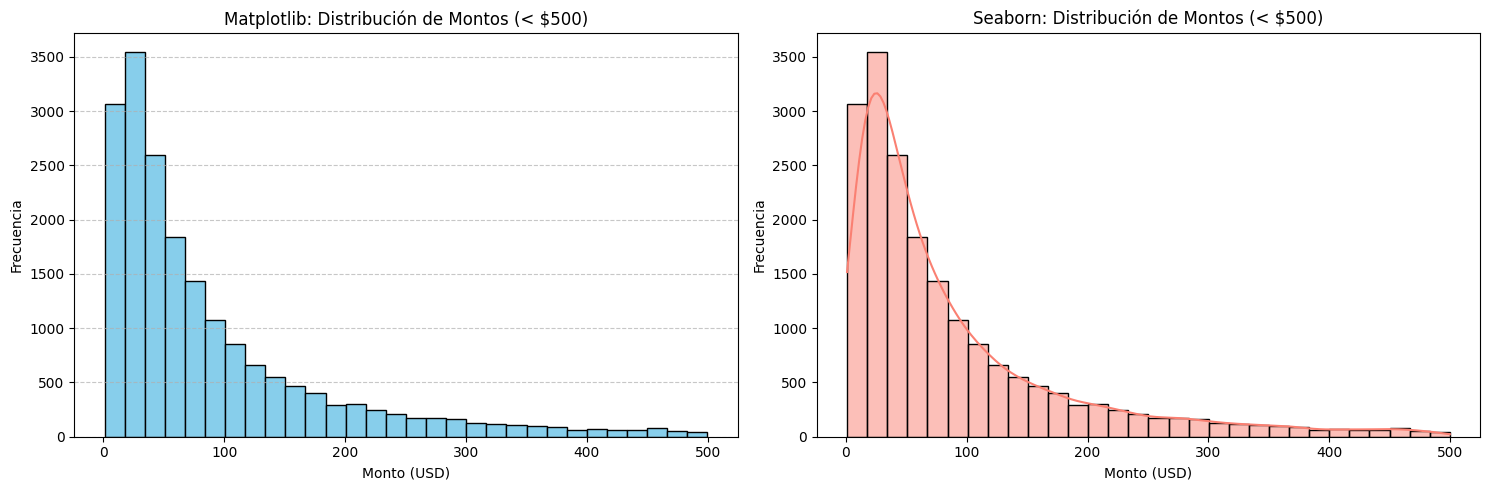

In [33]:
# Filtra los datos a montos menores a $500
df_filtered = df[df['amount_usd'] < 500]

# Crea figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Matplotlib
axes[0].hist(df_filtered['amount_usd'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Matplotlib: Distribución de Montos (< $500)')
axes[0].set_xlabel('Monto (USD)')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. Seaborn
sns.histplot(data=df_filtered, x='amount_usd', bins=30, color='salmon', kde=True, ax=axes[1])
axes[1].set_title('Seaborn: Distribución de Montos (< $500)')
axes[1].set_xlabel('Monto (USD)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Observaciones**

Ambas bibliotecas nos muestran una clara distribución asimétrica hacia la derecha para la variable `amount_usd`.
* **Distribución:** La gran mayoría de las transacciones son de montos bajos, concentrándose principalmente por debajo de los $50-100 USD.
* **Diferencia técnica:** Mientras que en Matplotlib creamos un histograma básico y estructurado, en Seaborn pudimos añadir de forma muy sencilla la estimación de densidad de la curva, la cual nos ayuda a suavizar visualmente cómo decrecen las frecuencias de las compras conforme aumenta el importe.

### Gráfico 2: Cantidad de transacciones por Categoría de Comercio

La variable `merchant_category` representa el tipo de negocio o el sector comercial en el que se ha realizado la transacción.


Vamos a visualizar con Matplotlib y Seaborn cuáles son los sectores comerciales (`merchant_category`) que reciben más transacciones utilizando un gráfico de barras.

/tmp/ipykernel_2463/3536744436.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='merchant_category', order=category_counts.index, palette='viridis', ax=axes[1])


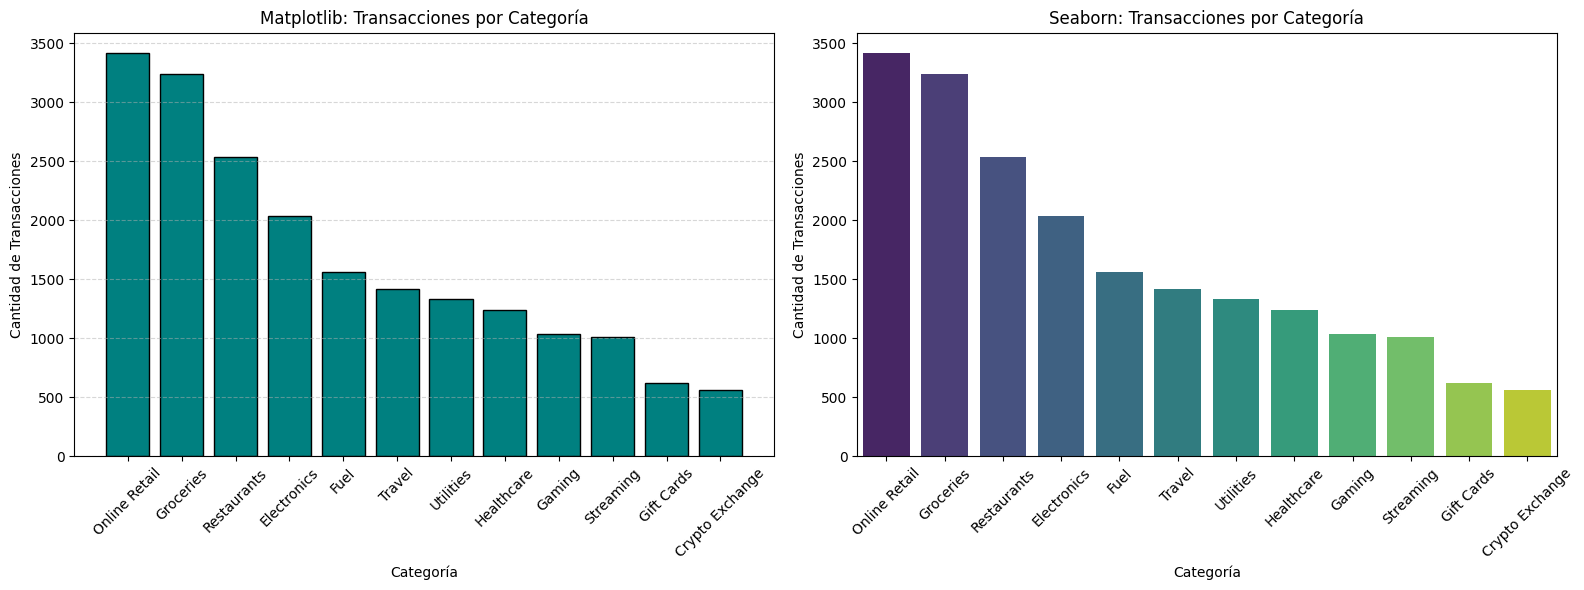

In [34]:
# Obtiene la cuenta de transacciones por categoría
category_counts = df['merchant_category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Matplotlib
axes[0].bar(category_counts.index, category_counts.values, color='teal', edgecolor='black')
axes[0].set_title('Matplotlib: Transacciones por Categoría')
axes[0].set_xlabel('Categoría')
axes[0].set_ylabel('Cantidad de Transacciones')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Seaborn
sns.countplot(data=df, x='merchant_category', order=category_counts.index, palette='viridis', ax=axes[1])
axes[1].set_title('Seaborn: Transacciones por Categoría')
axes[1].set_xlabel('Categoría')
axes[1].set_ylabel('Cantidad de Transacciones')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Observaciones**

En esta comparación de gráficos de barras observamos el volumen de actividad por sector comercial.
* **Volumen:** Los sectores de `Online Retail` (comercio electrónico) y `Groceries` (supermercados) lideran con diferencia la cantidad total de transacciones registradas.
* **Diferencia técnica:** En Matplotlib, la coloración es uniforme y requiere ajustes manuales detallados. Por su parte, Seaborn implementa de manera automática paletas de colores complejas (como `viridis`), lo cual facilita la distinción jerárquica visual de las columnas de mayor a menor volumen con mínimo código.

### Gráfico 3: Proporción de Transacciones Fraudulentas vs No Fraudulentas

La variable `is_fraud` nos dice si la transacción ha sido un fraude (`1`) o si no lo ha sido (`0`).


Vamos a realizar un mapa de calor con ambas bibliotecas para ver el procentaje de fraude (`is_fraud`) según el tipo de mercado (`merchant_category`).

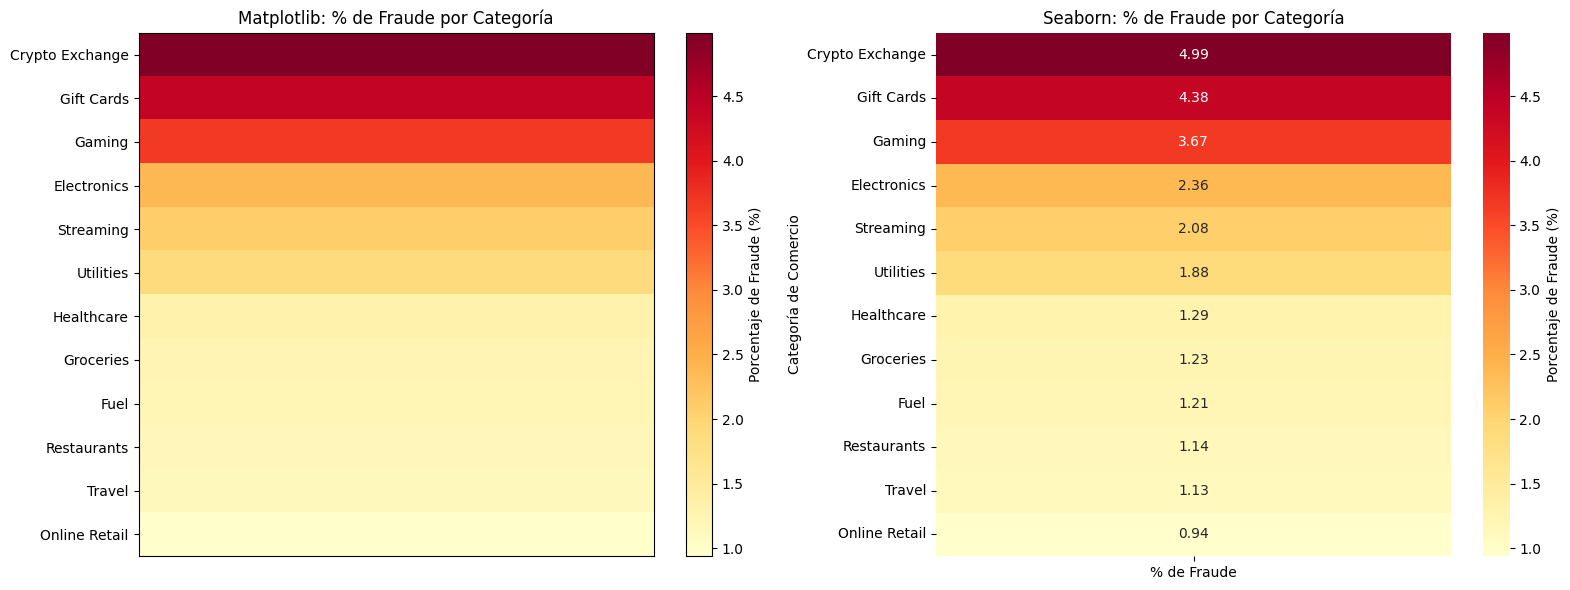

In [35]:
# Calcula el porcentaje de fraude por cada categoría de comercio
fraud_pivot = df.groupby('merchant_category')['is_fraud'].mean().to_frame() * 100
fraud_pivot.columns = ['% de Fraude']
fraud_pivot = fraud_pivot.sort_values(by='% de Fraude', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Matplotlib: Mapa de calor usando imshow()
im = axes[0].imshow(fraud_pivot.values, cmap='YlOrRd', aspect='auto')
axes[0].set_title('Matplotlib: % de Fraude por Categoría')
axes[0].set_yticks(range(len(fraud_pivot)))
axes[0].set_yticklabels(fraud_pivot.index)
axes[0].set_xticks([])
# Añadimos manualmente la barra de color
fig.colorbar(im, ax=axes[0], label='Porcentaje de Fraude (%)')

# 2. Seaborn: Mapa de calor con heatmap()
sns.heatmap(data=fraud_pivot, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Porcentaje de Fraude (%)'})
axes[1].set_title('Seaborn: % de Fraude por Categoría')
axes[1].set_ylabel('Categoría de Comercio')

plt.tight_layout()
plt.show()

**Observaciones**

El análisis de calor revela patrones críticos sobre la vulnerabilidad de ciertos comercios ante actividades fraudulentas.
* **Puntos de riesgo:** A pesar de tener volúmenes de transacción más bajos (vistos en el Gráfico 2), las categorías de `Crypto Exchange` (5.00%), `Gift Cards` (4.38%) y `Gaming` (3.67%) presentan los porcentajes de fraude más altos con diferencia.
* **Diferencia técnica:** Seaborn brilla especialmente en la generación de mapas de calor a través de `heatmap()`, permitiendo incluir anotaciones numéricas directas (`annot=True`) y formateo de decimales de manera integrada y estéticamente superior a la implementación manual con `imshow()` en Matplotlib.

### Gráfico 4: Relación entre Puntuación de Velocidad y Monto de la Transacción

La variable `velocity_score` es la puntuación de velocidad de la tarjeta.

Analizaremos con un gráfico de dispersión cómo interactúan el importe de la transacción (`amount_usd`, limitado a < $500) y la puntuación de velocidad de la tarjeta (`velocity_score`), coloreando por fraude para detectar zonas de alto riesgo combinadas.

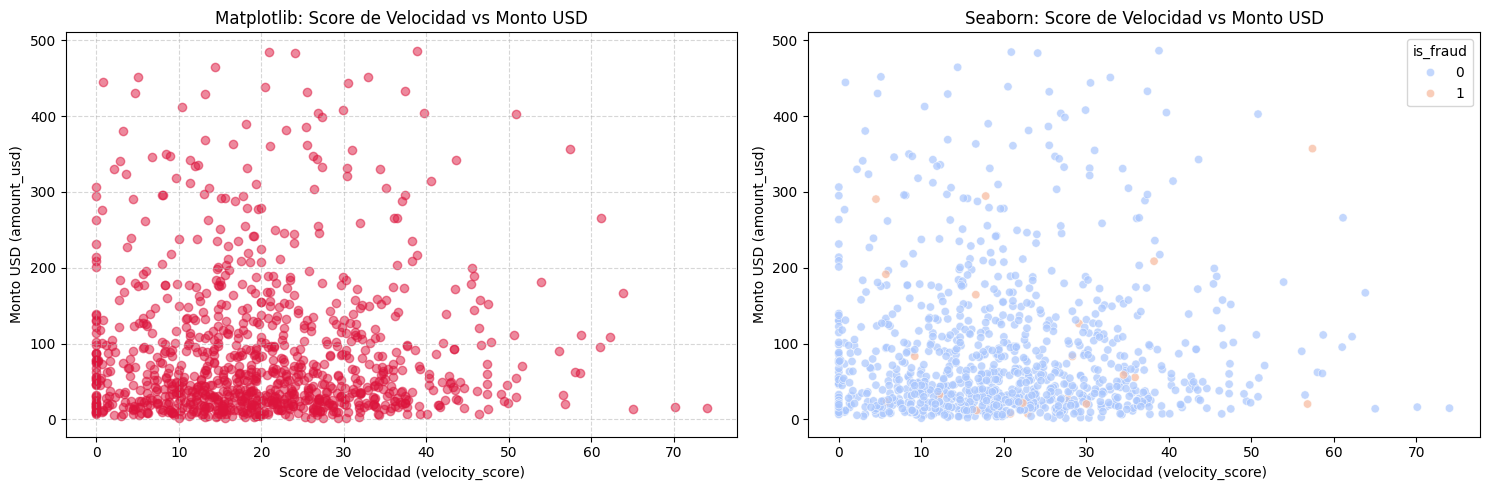

In [36]:
# Filtra importes menores a $500 y tomamos 1000 muestras aleatorias
df_filtered_sample = df[df['amount_usd'] < 500].sample(1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Matplotlib
axes[0].scatter(df_filtered_sample['velocity_score'], df_filtered_sample['amount_usd'], alpha=0.5, color='crimson')
axes[0].set_title('Matplotlib: Score de Velocidad vs Monto USD')
axes[0].set_xlabel('Score de Velocidad (velocity_score)')
axes[0].set_ylabel('Monto USD (amount_usd)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Seaborn (coloreando por si fue fraude o no)
sns.scatterplot(data=df_filtered_sample, x='velocity_score', y='amount_usd', hue='is_fraud', alpha=0.7, palette='coolwarm', ax=axes[1])
axes[1].set_title('Seaborn: Score de Velocidad vs Monto USD')
axes[1].set_xlabel('Score de Velocidad (velocity_score)')
axes[1].set_ylabel('Monto USD (amount_usd)')

plt.tight_layout()
plt.show()

**Observaciones**

El gráfico de dispersión revela la interacción y concentración de transacciones sospechosas según sus montos y velocidad de uso.
* **Distribución de fraude:** Podemos observar en la gráfica de Seaborn que las transacciones legítimas (puntos azules) se agrupan fuertemente en puntuaciones de velocidad menores a 40 y montos inferiores a $150 USD, mientras que los fraudes (puntos rojos) tienden a dispersarse e incrementarse en áreas de velocidad alta combinada con importes elevados, validando que una alta velocidad de transacciones es un indicador clave de riesgo.
* **Diferencia técnica:** Mientras que en Matplotlib obtenemos una visualización general sin distinción cromática rápida de categorías lógicas complejas, Seaborn nos permite segmentar y colorear de forma directa por una tercera variable categórica (`is_fraud`) con una sola línea de código usando el parámetro `hue`.

### Gráfico 5: Tendencia de Monto Promedio por Hora del Día (Gráfico de Líneas)
Utilizaremos un gráfico de líneas para analizar cómo varía el promedio de los montos de transacción (`amount_usd`) a lo largo de las 24 horas del día (`time_of_day_hour`).

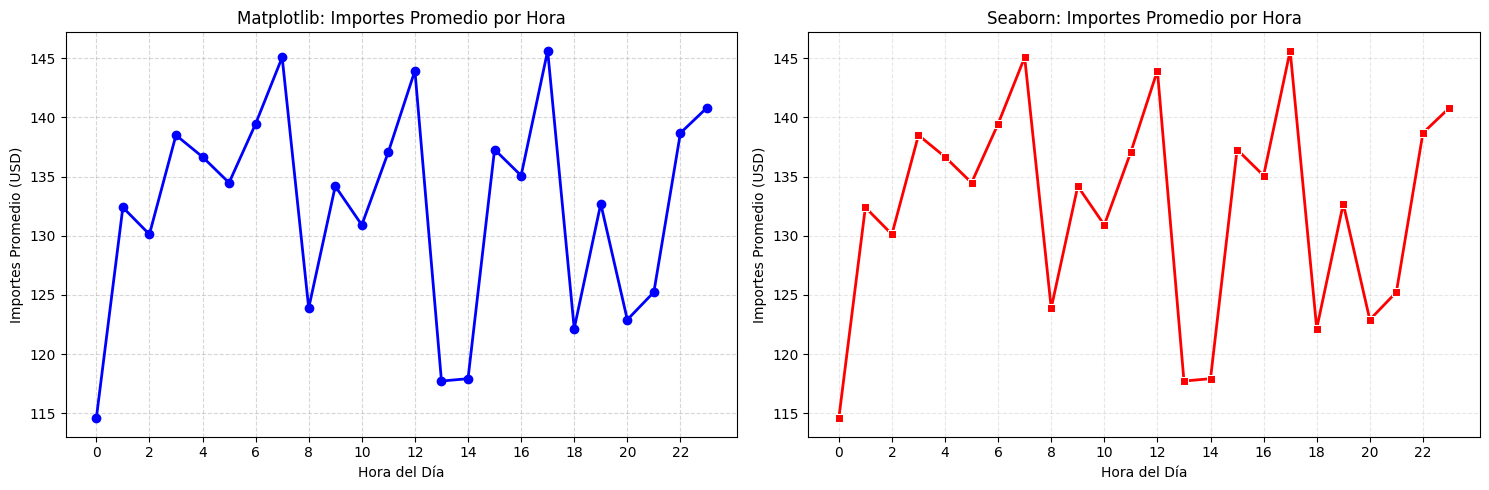

In [37]:
# Calcula el promedio del monto agrupado por hora del día
hourly_avg = df.groupby('time_of_day_hour')['amount_usd'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Matplotlib
axes[0].plot(hourly_avg['time_of_day_hour'], hourly_avg['amount_usd'], color='blue', marker='o', linestyle='-', linewidth=2)
axes[0].set_title('Matplotlib: Importes Promedio por Hora')
axes[0].set_xlabel('Hora del Día')
axes[0].set_ylabel('Importes Promedio (USD)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Seaborn
sns.lineplot(data=hourly_avg, x='time_of_day_hour', y='amount_usd', color='red', marker='s', linewidth=2, ax=axes[1])
axes[1].set_title('Seaborn: Importes Promedio por Hora')
axes[1].set_xlabel('Hora del Día')
axes[1].set_ylabel('Importes Promedio (USD)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

**Observaciones**

El gráfico de líneas nos ayuda a comprender los hábitos de gasto temporal de los usuarios.
* **Tendencias de horario:** El importe promedio por transacción experimenta picos notables a ciertas horas del día, alcanzando promedios máximos (cercanos a $145 USD) alrededor de las 07:00, 12:00 y 17:00 horas, lo que coincide con patrones habituales de compras y comidas. Los montos promedio más bajos ocurren durante la madrugada (00:00).
* **Diferencia técnica:** Ambas herramientas permiten personalizar estilos de línea y marcadores de manera muy similar, resultando en gráficos lineales altamente interpretables y limpios para el análisis de series temporales o tendencias continuas.

## StreamLit
**StreamLit** es una biblioteca de código abierto en Python que hace que sea fácil de crear y compartir aplicaciones web de *machine learning* y *data science*. Esto hace que podamos crear una aplicación web que nos deje interactuar con nuestro propio modelo.


🔗 Tutorial para integrar StreamLit en Google Colab: https://colab.research.google.com/github/schwallergroup/ai4chem_course/blob/main/notebooks/11%20-%20Model%20deployment/streamlit_tutorial.ipynb

### Instalación y Configuración
Para la instalación y configuración de **StreamLit** en *Google Colab*, instalaremos la biblioteca de StreamLit y una herramienta de túnel para conectarse a la plataforma.

In [38]:
!pip install streamlit
!pip install streamlit localtunnel

ERROR: Could not find a version that satisfies the requirement localtunnel (from versions: none)
ERROR: No matching distribution found for localtunnel


Una vez realida la instalación, tendremos que crear el archivo que contenga el código a mostrar en StreamLit. Al estar en Colab, podemos crear este archivo con el comando `%%writefile`.
Cuando ejecutes la celda, podrás verlo en los archivos guardados de Colab, en el panel izquierdo.

In [39]:
%%writefile app.py
import streamlit as st

st.title('¡Hola desde Google Colab!')
st.write('Esta es una aplicación de Streamlit funcionando en la nube.')

Overwriting app.py


Una vez tengamos el código preparado, podemos ejecutar Streamlit en segundo plano de la siguiente manera:

In [40]:
!streamlit run app.py &>/dev/null &

Cuando queramos acceder a nuestra aplicación web, utilizaremos `localtunnel` exponiendo el puerto `8501` (el puerto predeterminado de StreamLit) para obtener la URL pública de StreamLit.

In [41]:
import urllib.request
print("Tu IP pública es:", urllib.request.urlopen('https://icanhazip.com').read().decode('utf8').strip())

!npx localtunnel --port 8501

Tu IP pública es: 136.85.194.201
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸your url is: https://light-baboons-press.loca.lt
^C


### Visualización de gráficos en StreamLit

In [55]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

st.set_page_config(layout="wide")

st.title('Gráficas - Práctica de visualización de datos')
st.write('Esta es una aplicación de Streamlit que compara la visualización de datos con **Matplotlib** y **Seaborn** en un conjunto de datos de fraudes de tarjetas de crédito.')

# Carga los datos
@st.cache_data
def load_data():
    df = pd.read_csv('credit_card_fraud_2026.csv')
    return df

df = load_data()

# Crea pestañas para cada uno de los 5 gráficos
tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "1. Distribución Importes",
    "2. Transacciones por Categoría",
    "3. % de Fraude",
    "4. Velocidad vs Importe",
    "5. Tendencia por Hora"
])

# --- Gráfica 1 ---
with tab1:
    st.header("1. Distribución de importes de transacción (`amount_usd`)")
    df_filtered = df[df['amount_usd'] < 500]

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Matplotlib")
        fig1, ax1 = plt.subplots(figsize=(6, 4))
        ax1.hist(df_filtered['amount_usd'], bins=30, color='skyblue', edgecolor='black')
        ax1.set_title('Distribución de Importes (< $500)')
        ax1.set_xlabel('Monto (USD)')
        ax1.set_ylabel('Frecuencia')
        ax1.grid(axis='y', linestyle='--', alpha=0.7)
        st.pyplot(fig1)

    with col2:
        st.subheader("Seaborn")
        fig2, ax2 = plt.subplots(figsize=(6, 4))
        sns.histplot(data=df_filtered, x='amount_usd', bins=30, color='salmon', kde=True, ax=ax2)
        ax2.set_title('Distribución de Importes (< $500)')
        ax2.set_xlabel('Monto (USD)')
        ax2.set_ylabel('Frecuencia')
        st.pyplot(fig2)

# --- Gráfica 2 ---
with tab2:
    st.header("2. Cantidad de transacciones por Categoría de Comercio")
    category_counts = df['merchant_category'].value_counts()

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Matplotlib")
        fig1, ax1 = plt.subplots(figsize=(6, 4.5))
        ax1.bar(category_counts.index, category_counts.values, color='teal', edgecolor='black')
        ax1.set_title('Transacciones por Categoría')
        ax1.set_xlabel('Categoría')
        ax1.set_ylabel('Cantidad de Transacciones')
        plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
        ax1.grid(axis='y', linestyle='--', alpha=0.5)
        st.pyplot(fig1)

    with col2:
        st.subheader("Seaborn")
        fig2, ax2 = plt.subplots(figsize=(6, 4.5))
        sns.countplot(data=df, x='merchant_category', order=category_counts.index, palette='viridis', ax=ax2)
        ax2.set_title('Transacciones por Categoría')
        ax2.set_xlabel('Categoría')
        ax2.set_ylabel('Cantidad de Transacciones')
        plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
        st.pyplot(fig2)

# --- Gráfica 3 ---
with tab3:
    st.header("3. Proporción de Transacciones Fraudulentas (% de Fraude por Categoría)")
    fraud_pivot = df.groupby('merchant_category')['is_fraud'].mean().to_frame() * 100
    fraud_pivot.columns = ['% de Fraude']
    fraud_pivot = fraud_pivot.sort_values(by='% de Fraude', ascending=False)

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Matplotlib (imshow)")
        fig1, ax1 = plt.subplots(figsize=(6, 5.5))
        im = ax1.imshow(fraud_pivot.values, cmap='YlOrRd', aspect='auto')
        ax1.set_title('% de Fraude por Categoría')
        ax1.set_yticks(range(len(fraud_pivot)))
        ax1.set_yticklabels(fraud_pivot.index)
        ax1.set_xticks([])
        fig1.colorbar(im, ax=ax1, label='Porcentaje de Fraude (%)')
        st.pyplot(fig1)

    with col2:
        st.subheader("Seaborn (heatmap)")
        fig2, ax2 = plt.subplots(figsize=(6, 5.5))
        sns.heatmap(data=fraud_pivot, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax2, cbar_kws={'label': 'Porcentaje de Fraude (%)'})
        ax2.set_title('% de Fraude por Categoría')
        ax2.set_ylabel('Categoría de Comercio')
        st.pyplot(fig2)

# --- Gráfica 4 ---
with tab4:
    st.header("4. Relación entre Puntuación de Velocidad e Importe")
    df_filtered_sample = df[df['amount_usd'] < 500].sample(min(1000, len(df)), random_state=42)

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Matplotlib")
        fig1, ax1 = plt.subplots(figsize=(6, 4))
        ax1.scatter(df_filtered_sample['velocity_score'], df_filtered_sample['amount_usd'], alpha=0.5, color='crimson')
        ax1.set_title('Score de Velocidad vs Monto USD')
        ax1.set_xlabel('Score de Velocidad (velocity_score)')
        ax1.set_ylabel('Monto USD (amount_usd)')
        ax1.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig1)

    with col2:
        st.subheader("Seaborn (con Hue por Fraude)")
        fig2, ax2 = plt.subplots(figsize=(6, 4))
        sns.scatterplot(data=df_filtered_sample, x='velocity_score', y='amount_usd', hue='is_fraud', alpha=0.7, palette='coolwarm', ax=ax2)
        ax2.set_title('Score de Velocidad vs Monto USD')
        ax2.set_xlabel('Score de Velocidad (velocity_score)')
        ax2.set_ylabel('Monto USD (amount_usd)')
        st.pyplot(fig2)

# --- Gráfica 5 ---
with tab5:
    st.header("5. Tendencia de Monto Promedio por Hora del Día")
    hourly_avg = df.groupby('time_of_day_hour')['amount_usd'].mean().reset_index()

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Matplotlib")
        fig1, ax1 = plt.subplots(figsize=(6, 4))
        ax1.plot(hourly_avg['time_of_day_hour'], hourly_avg['amount_usd'], color='blue', marker='o', linestyle='-', linewidth=2)
        ax1.set_title('Importes Promedio por Hora')
        ax1.set_xlabel('Hora del Día')
        ax1.set_ylabel('Importes Promedio (USD)')
        ax1.set_xticks(range(0, 24, 2))
        ax1.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig1)

    with col2:
        st.subheader("Seaborn")
        fig2, ax2 = plt.subplots(figsize=(6, 4))
        sns.lineplot(data=hourly_avg, x='time_of_day_hour', y='amount_usd', color='red', marker='s', linewidth=2, ax=ax2)
        ax2.set_title('Importes Promedio por Hora')
        ax2.set_xlabel('Hora del Día')
        ax2.set_ylabel('Importes Promedio (USD)')
        ax2.set_xticks(range(0, 24, 2))
        ax2.grid(True, linestyle='--', alpha=0.3)
        st.pyplot(fig2)


Overwriting app.py


In [56]:
!streamlit run app.py &>/dev/null &

In [57]:
import urllib.request
print("Tu IP pública es:", urllib.request.urlopen('https://icanhazip.com').read().decode('utf8').strip())

!npx localtunnel --port 8501

Tu IP pública es: 136.85.194.201
⠙⠹⠸⠼⠴your url is: https://purple-onions-drop.loca.lt
^C
